# Variable selection using lasso

Instead of comparing models one by one, the lasso fits a Cox model with all the variables and a penalty on the size of the coefficients: it maximizes

$$
\log L(\beta)-\lambda\sum_j|\beta_j| .
$$

The penalty shrinks the coefficients, and makes some of them exactly zero, so the lasso selects variables. The larger $\lambda$, the fewer variables remain. We choose $\lambda$ by cross-validation.

The data are the survival times, in months, of 48 patients with multiple myeloma, with seven explanatory variables (the same data of the previous notebook).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter
from lifelines.exceptions import ConvergenceWarning
from sklearn.model_selection import LeaveOneOut
from ipywidgets import interact, SelectionSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
ref_color   = '#333333'
CLASS_COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#CC79A7', '#56B4E9', '#999999']

## The data

In [3]:
DatOriginal = pd.read_csv("data/multiple_myeloma_survival.dat", sep=r"\s+")
DatOriginal = DatOriginal.drop('patient', axis=1)

In [4]:
DatOriginal.head()

,time,status,age,sex,bun,ca,hb,pcells,protein
0,13,1,66,1,25,10,14.6,18,1
1,52,0,66,1,13,11,12.0,100,0
2,6,1,53,2,15,13,11.4,33,1
3,40,1,69,1,10,10,10.2,30,1
4,10,1,65,1,20,10,13.2,66,0


## Cross-validation

For each $\lambda$ we leave one patient out, fit the model with the others, and measure how much that patient adds to the partial log-likelihood, evaluated at the coefficients $\hat\beta_{(-i)}$ that were estimated without the patient:

$$
CV(\lambda)=\sum_i\left\{\log L(\hat\beta_{(-i)})-\log L_{(-i)}(\hat\beta_{(-i)})\right\},
$$

where $L$ uses all the patients and $L_{(-i)}$ all but the $i$-th. We keep the $\lambda$ with the largest value.

In [5]:
# Partial log-likelihood of a dataset using Breslow approximation and the beta-coefficients of a fit Cox PH
def LogLikelihood(cox, data):
    BetaTimesX = cox.predict_log_partial_hazard(data).values

    DeathTimes = data.loc[data['status']==1, 'time'].unique()
    Aux1, Aux2 = 0, 0
    for t in DeathTimes:
        ObsRisk = (data['time']>=t)
        ObsDeath = (data['time']==t) & (data['status']>=1)
        NumberDeaths = sum(ObsDeath)

        Aux1 += sum(ObsDeath * BetaTimesX)
        Aux2 += NumberDeaths * np.log(sum(ObsRisk * np.exp(BetaTimesX)))

    loglikelihood = Aux1 - Aux2
    return loglikelihood

This cell fits 2400 models and takes a few minutes. With a large penalty some fits do not converge completely and `lifelines` warns about it; those warnings are silenced here.

In [6]:
LambdaList = np.linspace(0, 0.3)

CvEstimate = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)

    for l in LambdaList:
        CvMetric = []
        Loo = LeaveOneOut()

        for TrainIds, TestIds in Loo.split(DatOriginal):
            XTrain, XTest = DatOriginal.iloc[TrainIds], DatOriginal.iloc[TestIds]

            Model = CoxPHFitter(l1_ratio=1, penalizer=l)
            Model.fit(XTrain, "time", "status")

            # Both terms are computed with the same function. The attribute log_likelihood_ of the
            # model cannot be used for the second one: it includes the penalty.
            LoglikeWhole = LogLikelihood(Model, DatOriginal)
            LoglikeTrain = LogLikelihood(Model, XTrain)
            CvMetric.append(LoglikeWhole - LoglikeTrain)

        CvEstimate.append(sum(CvMetric))

In [7]:
LambdaHat = LambdaList[np.argmax(CvEstimate)]
LambdaHat

np.float64(0.08571428571428572)

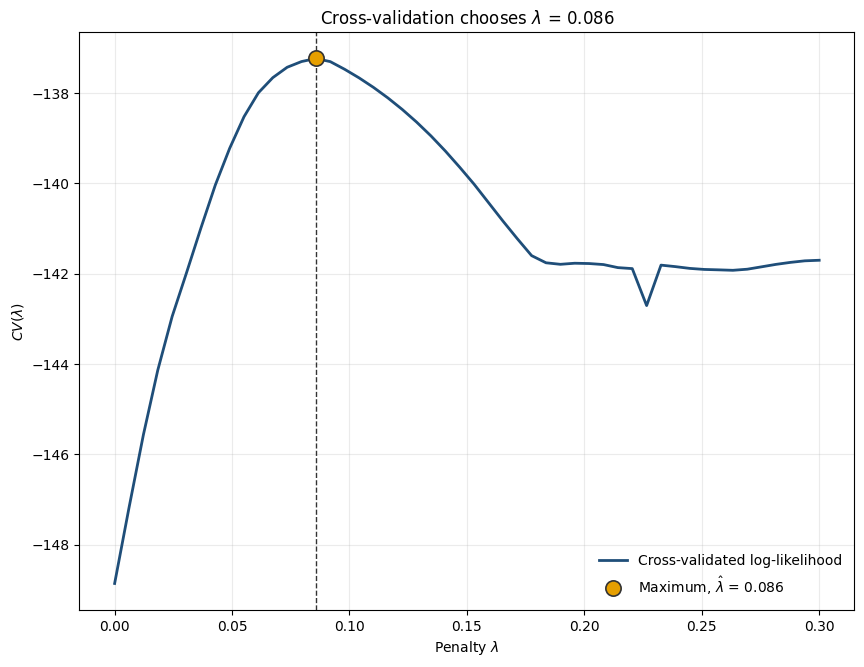

In [8]:
plt.figure(figsize=(10, 7.5))
plt.plot(LambdaList, CvEstimate, color=line_color, lw=2, label='Cross-validated log-likelihood')
plt.axvline(LambdaHat, color=ref_color, lw=1, ls='--')
plt.plot(LambdaHat, max(CvEstimate), 'o', color=opt_color, markersize=11, markeredgecolor=ref_color, markeredgewidth=1.2,
         label=fr'Maximum, $\hat\lambda$ = {LambdaHat:.3f}', zorder=5)

plt.xlabel(r'Penalty $\lambda$')
plt.ylabel(r'$CV(\lambda)$')
plt.title(fr'Cross-validation chooses $\lambda$ = {LambdaHat:.3f}')
plt.legend(loc='lower right', frameon=False)
plt.grid(True, alpha=0.25)

## The path of the coefficients

The coefficients for each $\lambda$, fitted with all the patients. The variables are in very different units, so in the second panel each coefficient is multiplied by the standard deviation of its variable: it is the change in the log-hazard for an increase of one standard deviation, and the variables can be compared.

In [9]:
Params = {}

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)

    for l in LambdaList:
        Model = CoxPHFitter(l1_ratio=1, penalizer=l).fit(DatOriginal, "time", "status")
        Params[l] = Model.params_

Params = pd.DataFrame(Params).T
ParamsStandardized = Params * DatOriginal[Params.columns].std()

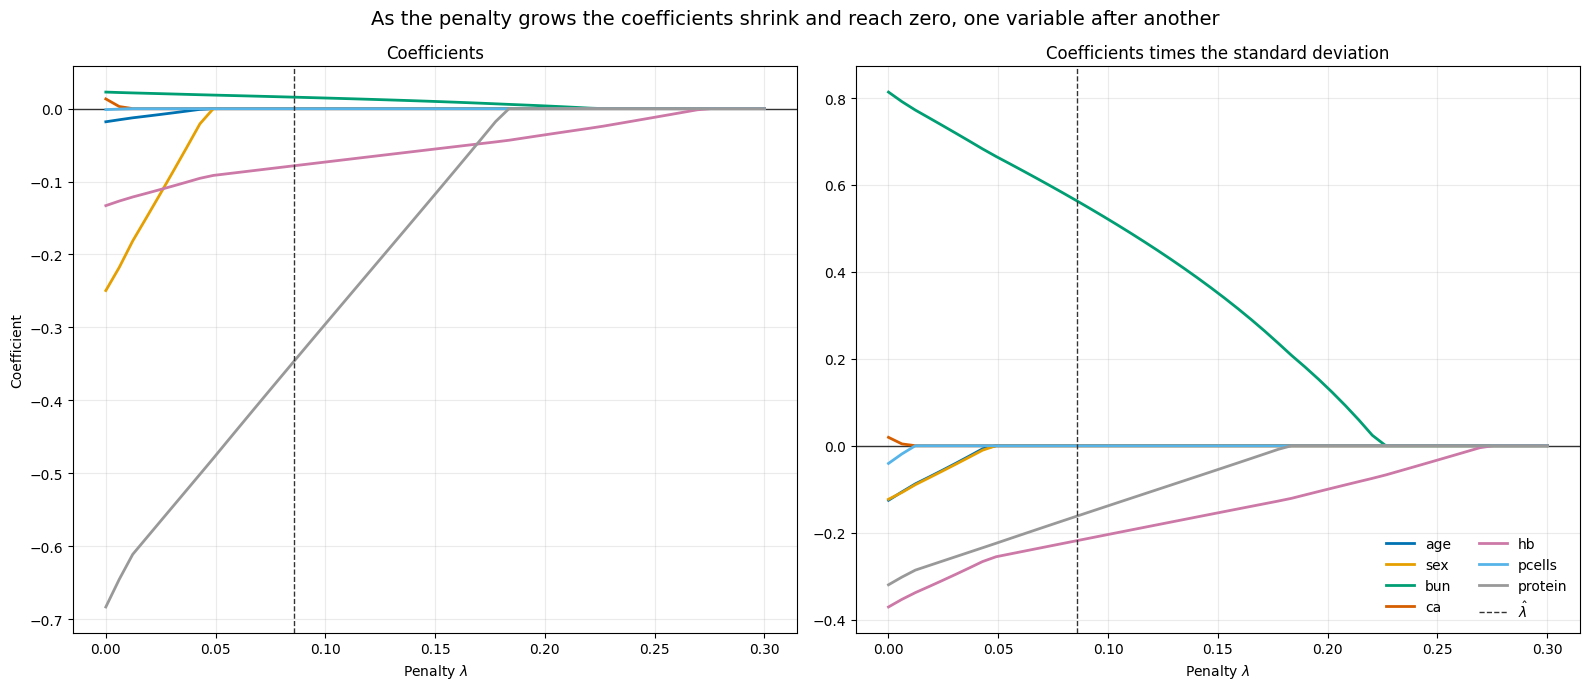

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, path, title in zip(axes, [Params, ParamsStandardized], ['Coefficients', 'Coefficients times the standard deviation']):
    ax.axhline(0, color=ref_color, lw=1)
    for variable, color in zip(path.columns, CLASS_COLORS):
        ax.plot(path.index, path[variable], color=color, lw=2, label=variable)
    ax.axvline(LambdaHat, color=ref_color, lw=1, ls='--', label=r'$\hat\lambda$')
    ax.set_xlabel(r'Penalty $\lambda$')
    ax.set_title(title)
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Coefficient')
axes[1].legend(loc='lower right', frameon=False, ncol=2)
fig.suptitle('As the penalty grows the coefficients shrink and reach zero, one variable after another', fontsize=14)
plt.tight_layout()

Move the slider to see which variables remain in the model for each penalty (this cell needs a running kernel).

In [11]:
def PlotSelected(ax, l):
    values = ParamsStandardized.loc[l]
    selected = values.abs() > 1e-3
    ax.axvline(0, color=ref_color, lw=1)
    ax.barh(values.index[::-1], values[::-1], color=np.where(selected[::-1], line_color, '#cccccc'), edgecolor='white')
    ax.set_xlim(-0.9, 0.9)
    ax.set_xlabel('Coefficient times the standard deviation')
    ax.set_title(fr'$\lambda$ = {l:.3f}: {selected.sum()} variables remain')
    ax.grid(True, axis='x', alpha=0.25)

def interactive_selected(penalty):
    fig, ax = plt.subplots(figsize=(10, 6))
    PlotSelected(ax, penalty)
    plt.show()

interact(interactive_selected,
         penalty=SelectionSlider(options=[(f'{l:.3f}', l) for l in LambdaList], value=LambdaHat, description='lambda'));

interactive(children=(SelectionSlider(description='lambda', index=14, options=(('0.000', np.float64(0.0)), ('0…

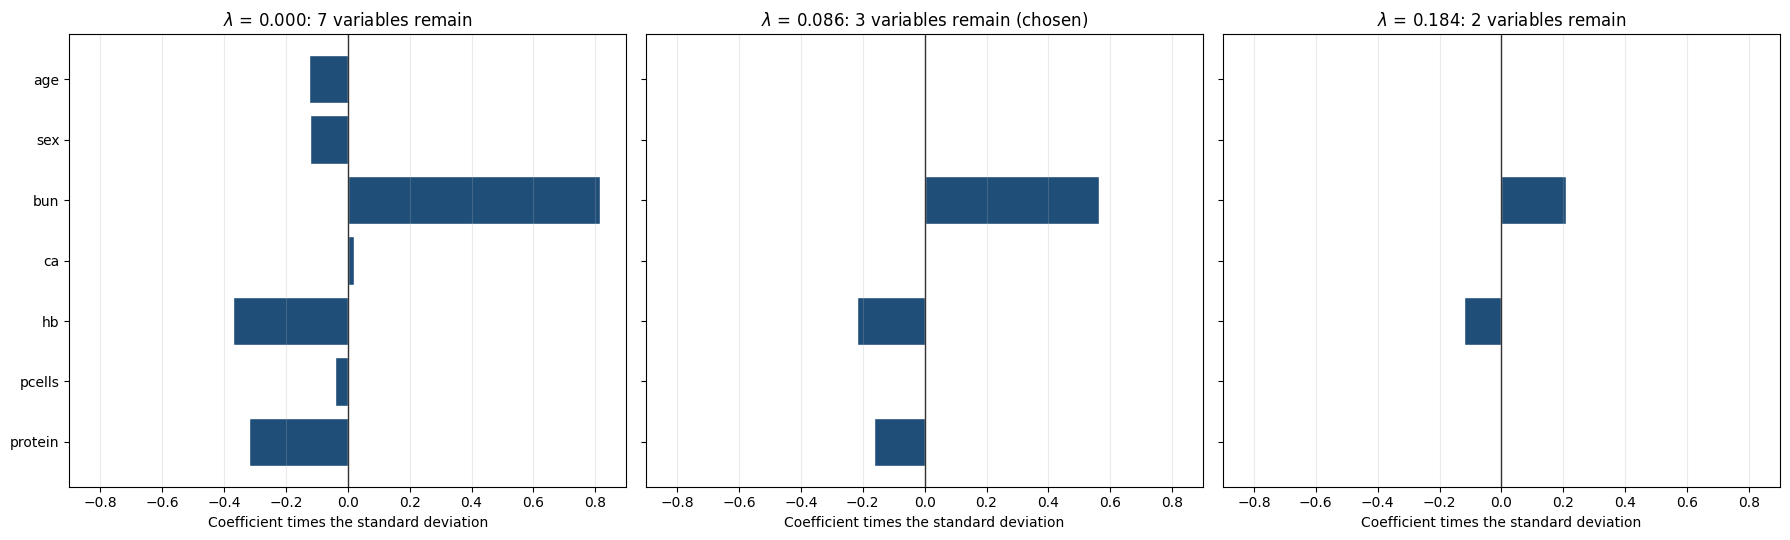

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, l in zip(axes, [LambdaList[0], LambdaHat, LambdaList[30]]):
    PlotSelected(ax, l)
axes[1].set_title(axes[1].get_title() + ' (chosen)')
plt.tight_layout()

## The chosen model

In [13]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    Model = CoxPHFitter(l1_ratio=1, penalizer=LambdaHat).fit(DatOriginal, "time", "status")

In [14]:
Model.params_.round(3)

covariate
age       -0.000
sex       -0.000
bun        0.016
ca        -0.000
hb        -0.078
pcells     0.000
protein   -0.346
Name: coef, dtype: float64

We deduce from this analysis that we only need the variables bun, hb, and protein.